# MTG FCI before/after slider

Drag the slider to compare two FCI frames (2026-07-15, 14:30 vs 14:40 UTC).
The slider runs in the browser, so it is instant - no Python re-plotting.

In [1]:
import base64, io, urllib.request
import numpy as np
from PIL import Image
from IPython.display import HTML, display

def to_b64(img):
    a = np.asarray(img)
    if a.dtype != np.uint8:                      # float images (0-1 or 0-255)
        a = a * 255 if a.max() <= 1 else a
        a = np.clip(a, 0, 255).astype(np.uint8)
    buf = io.BytesIO()
    Image.fromarray(a).save(buf, format="PNG")
    return base64.b64encode(buf.getvalue()).decode()

def compare_html(img1, img2, width=874):
    a, b = to_b64(img1), to_b64(img2)
    return f"""<div style="position:relative; width:{width}px; max-width:100%">
  <img src="data:image/png;base64,{a}" style="width:100%; display:block">
  <img src="data:image/png;base64,{b}"
       style="width:100%; position:absolute; top:0; left:0; clip-path:inset(0 50% 0 0)">
  <input type="range" min="0" max="100" value="50" step="0.1" style="width:100%"
         oninput="this.previousElementSibling.style.clipPath =
                  'inset(0 ' + (100 - this.value) + '% 0 0)'">
</div>"""


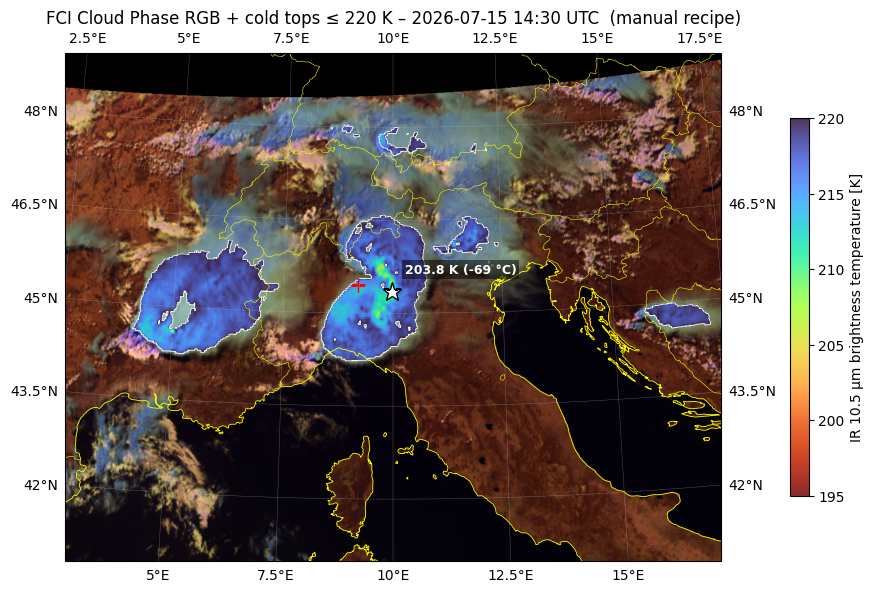
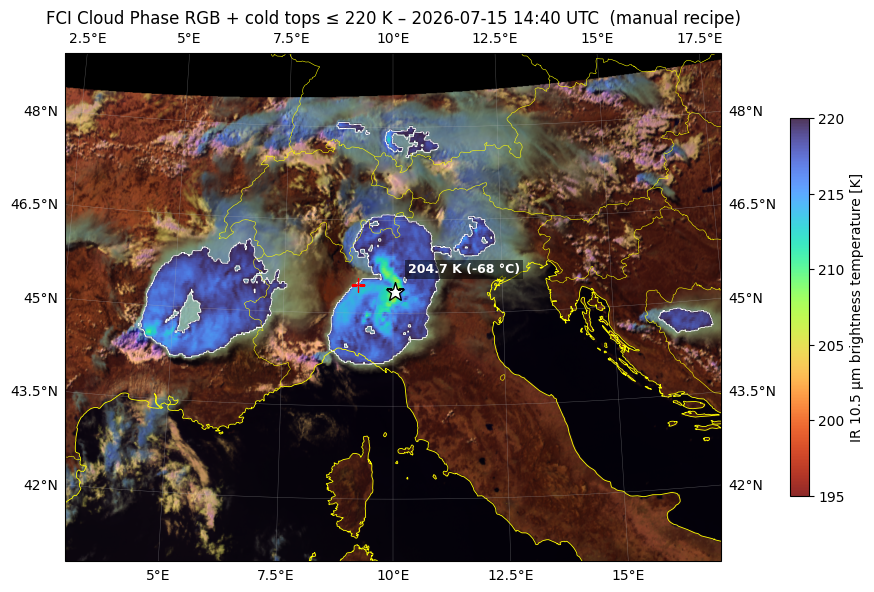

In [2]:
# Load the two example frames from the repo (replace with your own img1 / img2 arrays)
base = "https://raw.githubusercontent.com/Sladekd/MTG_slider/main/images/"
img1 = np.asarray(Image.open(urllib.request.urlopen(base + "img1.png")).convert("RGB"))
img2 = np.asarray(Image.open(urllib.request.urlopen(base + "img2.png")).convert("RGB"))

html = compare_html(img1, img2)
display(HTML(html))   # left of the slider = img2 (14:40 UTC), right = img1 (14:30 UTC)